First 5 records:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Dataset Shape: (200, 5)

Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Summary Statistics:
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.00

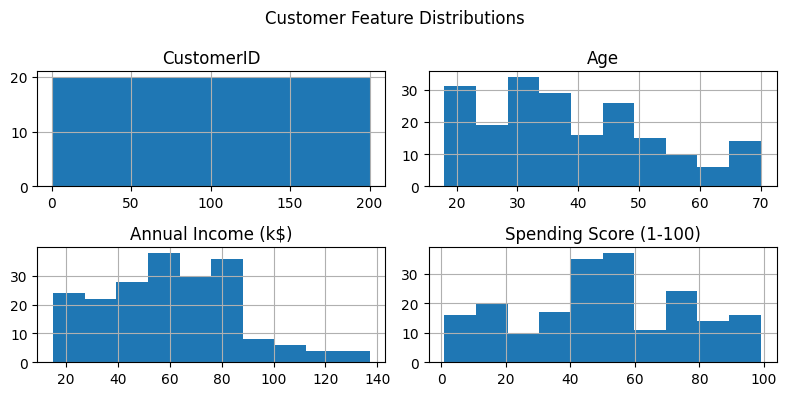

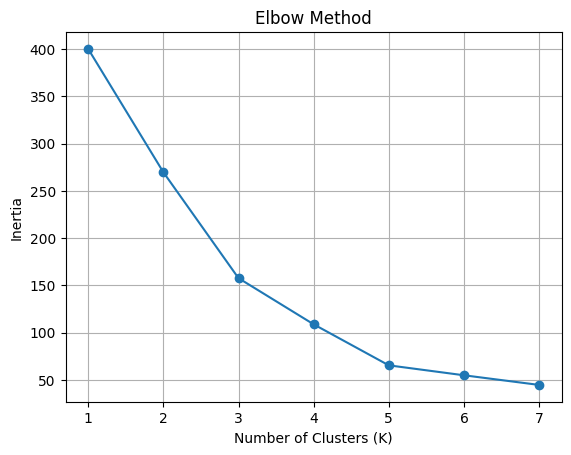

Enter the selected number of clusters K: 5


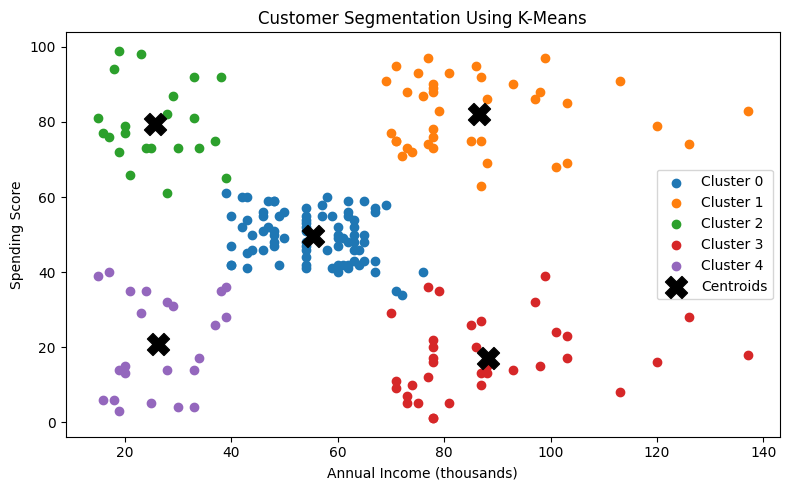


Cluster Characteristics:
         CustomerCount  AverageIncome  AverageSpending
Cluster                                               
0                   81          55.30            49.52
1                   39          86.54            82.13
2                   22          25.73            79.36
3                   35          88.20            17.11
4                   23          26.30            20.91


In [3]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Create a sample customer dataset
df = pd.read_csv("/content/Mall_Customers - Mall_Customers.csv")

print("First 5 records:")
print(df.head())

# 2. Inspect data and missing values
print("\nDataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())

print("\nSummary Statistics:")
print(df.describe())

# Visualize feature distributions
df.hist(figsize=(8, 4), bins=10)
plt.suptitle("Customer Feature Distributions")
plt.tight_layout()
plt.show()

# 3. Select and scale features
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Elbow method
inertias = []

for k in range(1, 8):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.plot(range(1, 8), inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(1, 8))
plt.grid(True)
plt.show()

# 5. Fit K-Means using a selected K
# Choose K after inspecting the elbow plot.
k = int(input("Enter the selected number of clusters K: "))

if k < 1 or k > 7:
    raise ValueError("K must be between 1 and 7.")

kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

# Convert centroids back to original units
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

# 6. Plot clusters and centroids
plt.figure(figsize=(8, 5))

for cluster in sorted(df["Cluster"].unique()):
    cluster_data = df[df["Cluster"] == cluster]
    plt.scatter(
        cluster_data["Annual Income (k$)"],
        cluster_data["Spending Score (1-100)"],
        label=f"Cluster {cluster}"
    )

plt.scatter(
    centroids[:, 0], centroids[:, 1],
    marker="X", s=250, color="black", label="Centroids"
)

plt.xlabel("Annual Income (thousands)")
plt.ylabel("Spending Score")
plt.title("Customer Segmentation Using K-Means")
plt.legend()
plt.tight_layout()
plt.show()

# 7. Describe each customer segment
print("\nCluster Characteristics:")
summary = df.groupby("Cluster").agg(
    CustomerCount=("Cluster", "size"),
    AverageIncome=("Annual Income (k$)", "mean"),
    AverageSpending=("Spending Score (1-100)", "mean")
).round(2)

print(summary)
